# Cathode pin comparison at fixed height
## Shapes, taper, size, gap and count — with explicit comparison rules

**Main question:** at the same penetration height, which pin shapes and arrays provide the most exposed geometric area on the cathode?

This new notebook makes **height the primary controlled variable** and lets material volume change. It does not replace the earlier fixed-volume notebook. It includes truncated cones and square pyramids (frusta), plus pointed and straight endpoints.

**Run all cells.** Read the “FIXED / VARIED / CALCULATED” description before each figure. Calculated example outputs are included. Edit section 1 and rerun to use other settings.

### What is calculated, not measured?
- Total exposed cathode area A, including the remaining base face, pin sidewalls and pin tops.
- Added area ΔA, area enhancement A/A₀, pin material volume and packing counts.
- Exact ideal geometry; **no prediction of adhesion, bubbles, wetting, current or voltage**.

The experiment report gives electrode strips **20 × 1 mm** (mini) and **20 × 5 mm** (large), p. 5, Figure 3. We interpret one full strip face as gel-contacting. Pins project normal to that face. The actual wetted overlap should be measured. Pin heights and fabrication limits below are assumptions, not values established by that report.

### Road map
| Study | Fixed | Compared / varied |
|---|---|---|
| A | h, base bounding width, gap, exact array/count | Cross-section family and taper |
| A2 | h, individual footprint area, gap, exact array/count | Circular versus square cross-section and taper |
| B | h, cathode size, shape/taper per panel | Base width and gap; fitting count is calculated |
| C | h, width, shape/taper per panel | Gap and integer count |
| D | Gap, exact array/count, shape/taper per panel | Height and radius / square side width |
| E | Cathode and feature bounds | Repeat study B at several fixed heights |

**Vocabulary:** base diameter d = 2R for round pins; square base side a. The shared width w means d or a. Clear gap g is edge-to-edge at the base. Pitch p = w + g. Top ratio t = top width/base width. The pyramid base is square.


**New: section F directly compares more pins versus wider pins for one selected shape, at fixed height and gap.**


In [1]:
# If needed, uncomment and run in your notebook kernel:
# %pip install numpy matplotlib plotly
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import csv, json, math
from IPython.display import display, Markdown, HTML
plt.rcParams.update({'font.size': 11, 'figure.figsize': (10, 5)})
try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False
    print('Static plots will work. Install plotly for rotatable plots: %pip install plotly')


## 1. Settings — change these first

All lengths are **mm**, areas **mm²**, volumes **mm³**. Height is penetration into the gel, not the narrow dimension across the cathode face.

`H_MAIN = 0.5` is an illustrative starting height; it is not experimentally validated. Compare it with `HEIGHTS`. Minimum gap and width also require fabrication confirmation. **No aspect-ratio cap is imposed by default**; set one only when justified. A fixed height and finite width bounds already make the search bounded.

The top-to-base ratio t varies the shape at the **same final height and base size**. This is not cutting a fixed original cone at successively lower heights. Top edge rounding is not modeled.

In [2]:
SETUP = 'mini'  # 'mini' or 'large'
L, W = {'mini': (20., 1.), 'large': (20., 5.)}[SETUP]
MARGIN = 0.05
H_MAIN = 0.08
HEIGHTS = [0.05, 0.08, 1.0, 0.3]
WIDTH_MIN, WIDTH_MAX = 0.030, 0.20
GAP_MIN, GAP_MAX = 0.030, 0.2
N_WIDTH, N_GAP = 100, 80
# Optional envelope aspect ratio limit h / base width. None means no assumed cap.
MAX_ASPECT_RATIO = None
T_TRUNCATED = 0.50
# Controlled comparison A (same array, not necessarily maximum packing):
REF_WIDTH, REF_GAP = 0.05, 0.05
REF_NX, REF_NY = 30, 3
# Study D holds this exact layout and this gap fixed:
D_NX, D_NY, D_GAP = 10, 2, 0.20
# Optional known volume of the gel compartment into which pins protrude:
COMPARTMENT_VOLUME_MM3 = None  # do not guess from the whole mold volume
OUT = Path('fixed_height_cathode_results') / SETUP
OUT.mkdir(parents=True, exist_ok=True)
A0 = L * W
DESIGNS = [
    dict(label='Cylinder', family='round', t=1.0),
    dict(label='Truncated cone', family='round', t=T_TRUNCATED),
    dict(label='Cone (reference)', family='round', t=0.0),
    dict(label='Square prism', family='square', t=1.0),
    dict(label='Truncated pyramid', family='square', t=T_TRUNCATED),
    dict(label='Pyramid (reference)', family='square', t=0.0),
]
assert L>2*MARGIN and W>2*MARGIN and MARGIN>=0
assert 0<WIDTH_MIN<WIDTH_MAX and 0<GAP_MIN<GAP_MAX
assert H_MAIN>0 and all(h>0 for h in HEIGHTS) and 0<T_TRUNCATED<1
assert MAX_ASPECT_RATIO is None or MAX_ASPECT_RATIO>0
assert REF_NX>=1 and REF_NY>=1 and D_NX>=1 and D_NY>=1
widths=np.linspace(WIDTH_MIN,WIDTH_MAX,N_WIDTH)
gaps=np.linspace(GAP_MIN,GAP_MAX,N_GAP)
print(f'{SETUP}: cathode face {L:g} × {W:g} mm; A₀ = {A0:g} mm²')
print(f'Main fixed height {H_MAIN:g} mm; comparison array {REF_NX} × {REF_NY} = {REF_NX*REF_NY} pins')
print('Volume varies. Aspect-ratio cap:', MAX_ASPECT_RATIO)


mini: cathode face 20 × 1 mm; A₀ = 20 mm²
Main fixed height 0.08 mm; comparison array 30 × 3 = 90 pins
Volume varies. Aspect-ratio cap: None


## 2. Geometry and exact formulas

For **one pin**, B is its base footprint, T its exposed top and S its sidewall area. The attachment base is buried and must not be counted:

$$A=A_0+N(S+T-B),\quad \Delta A=A-A_0,\quad V=Nv.$$

**Round frustum**: base radius R = w/2, top radius r = tR.

$$S=\pi(R+r)\sqrt{h^2+(R-r)^2},\quad B=\pi R^2,\quad T=\pi r^2,$$
$$v=\frac{\pi h}{3}(R^2+Rr+r^2).$$

**Square frustum**: base side a = w, top side b = ta.

$$S=2(a+b)\sqrt{h^2+[(a-b)/2]^2},\quad B=a^2,\quad T=b^2,$$
$$v=\frac{h}{3}(a^2+ab+b^2).$$

At t = 0 these become the pointed shapes; at t = 1 the straight shapes. For straight pins T = B, so added area is just NS. Both frustum families include a flat top for t > 0.

A **fixed-width shape comparison** gives circular and square bases the same enclosing width, not the same footprint area. Study A2 repeats the comparison with equal individual footprint area. Always state the normalization.

In [3]:
def geometry(family, w, h, t, N=1):
    """Vectorized exact geometry. w is base diameter or square side."""
    if np.any(np.asarray(w)<=0) or np.any(np.asarray(h)<=0):
        raise ValueError('Width and height must be positive.')
    if np.any(np.asarray(t)<0) or np.any(np.asarray(t)>1):
        raise ValueError('Top ratio must be between 0 and 1.')
    if family=='round':
        R=w/2; r=t*R
        B=np.pi*R**2; T=np.pi*r**2
        S=np.pi*(R+r)*np.sqrt(h*h+(R-r)**2)
        v=np.pi*h*(R*R+R*r+r*r)/3
    elif family=='square':
        a=w; b=t*a
        B=a*a; T=b*b
        S=2*(a+b)*np.sqrt(h*h+((a-b)/2)**2)
        v=h*(a*a+a*b+b*b)/3
    else: raise ValueError(family)
    added=N*(S+T-B)
    return dict(area=A0+added, added=added, ratio=(A0+added)/A0,
                volume=N*v, base=B, top=T, lateral=S)

def fits(nx,ny,w,g):
    return ((nx*w+(nx-1)*g<=L-2*MARGIN+1e-10)
           &(ny*w+(ny-1)*g<=W-2*MARGIN+1e-10))

def feature_ok(w,h,g):
    ok=(np.asarray(w)>=WIDTH_MIN-1e-12)&(np.asarray(w)<=WIDTH_MAX+1e-12)&(np.asarray(g)>=GAP_MIN-1e-12)
    if MAX_ASPECT_RATIO is not None: ok=ok&(h/w<=MAX_ASPECT_RATIO)
    return ok

def capacity(w,g):
    nx=np.maximum(0,np.floor((L-2*MARGIN+g)/(w+g)+1e-10)).astype(int)
    ny=np.maximum(0,np.floor((W-2*MARGIN+g)/(w+g)+1e-10)).astype(int)
    return nx,ny

# Checks against independent formulas and limiting shapes.
w,h,N=.2,.5,20
assert np.isclose(geometry('round',w,h,1,N)['added'],N*np.pi*w*h)
assert np.isclose(geometry('square',w,h,1,N)['added'],N*4*w*h)
assert np.isclose(geometry('round',w,h,0,N)['volume'],N*np.pi*(w/2)**2*h/3)
assert np.isclose(geometry('square',w,h,0,N)['volume'],N*w*w*h/3)
assert np.isclose(geometry('round',w,h,.5,N)['area'],
    A0+N*(np.pi*(.1+.05)*np.sqrt(.5**2+.05**2)+np.pi*.05**2-np.pi*.1**2))
# Independently verify square frustum side triangles/trapezoids.
a,b=.2,.1
assert np.isclose(geometry('square',a,h,.5,N)['added'],
                 N*(4*(a+b)/2*np.sqrt(h*h+((a-b)/2)**2)+b*b-a*a))
assert fits(*capacity(.2,.1),.2,.1)
print('Geometry and packing checks passed.')

def table(rows, headings):
    display(Markdown('| '+' | '.join(headings)+' |\n|'+ '|'.join(['---']*len(headings))+'|\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

def save_csv(path, rows):
    if rows:
        with path.open('w',newline='',encoding='utf-8') as f:
            wr=csv.DictWriter(f,fieldnames=list(rows[0]));wr.writeheader();wr.writerows(rows)


Geometry and packing checks passed.


## A. Isolate shape: SAME height, SAME base bounding width, SAME count

**FIXED:** h = H_MAIN, base diameter/side = REF_WIDTH, gap = REF_GAP, and exact REF_NX × REF_NY array. Cathode and margins are unchanged.

**VARIED:** round versus square cross-section and taper t. **CALCULATED:** area, area gain and material volume. Height, size and count are not optimized here.

This answers “what does changing shape alone do?” Square bases occupy more area than circular bases of equal diameter/side width. Volume is deliberately free. The default includes pointed shapes only as reference endpoints; the truncated candidates have flat tops.

| Shape | Top/base ratio | Total area (mm²) | Gain vs flat | Pin volume (mm³) |
|---|---|---|---|---|
| Cylinder | 1.00 | 21.13 | 5.7% | 0.014 |
| Truncated cone | 0.50 | 20.73 | 3.6% | 0.008 |
| Cone (reference) | 0.00 | 20.42 | 2.1% | 0.005 |
| Square prism | 1.00 | 21.44 | 7.2% | 0.018 |
| Truncated pyramid | 0.50 | 20.92 | 4.6% | 0.011 |
| Pyramid (reference) | 0.00 | 20.53 | 2.6% | 0.006 |

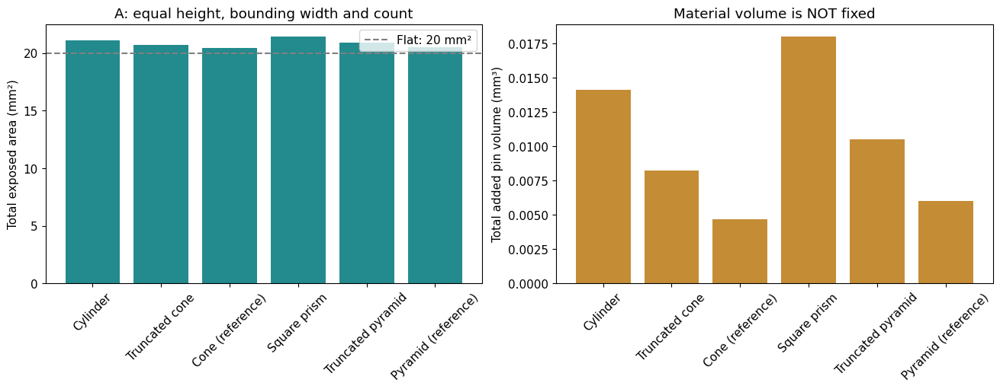

In [4]:
NREF=REF_NX*REF_NY
assert fits(REF_NX,REF_NY,REF_WIDTH,REF_GAP), 'Reference array does not fit: reduce count or base width/gap.'
assert feature_ok(REF_WIDTH,H_MAIN,REF_GAP), 'Reference features violate the chosen bounds.'
controlled=[]
for d in DESIGNS:
    q=geometry(d['family'],REF_WIDTH,H_MAIN,d['t'],NREF)
    controlled.append(dict(label=d['label'],family=d['family'],top_ratio=d['t'],
        width_mm=REF_WIDTH,height_mm=H_MAIN,gap_mm=REF_GAP,count=NREF,
        area_mm2=float(q['area']),gain_percent=float((q['ratio']-1)*100),volume_mm3=float(q['volume'])))
table([[r['label'],f"{r['top_ratio']:.2f}",f"{r['area_mm2']:.2f}",f"{r['gain_percent']:.1f}%",f"{r['volume_mm3']:.3f}"] for r in controlled],
      ['Shape','Top/base ratio','Total area (mm²)','Gain vs flat','Pin volume (mm³)'])
fig,axs=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
labels=[r['label'] for r in controlled]
axs[0].bar(labels,[r['area_mm2'] for r in controlled],color='#238b8e')
axs[0].axhline(A0,color='gray',ls='--',label=f'Flat: {A0:g} mm²');axs[0].legend()
axs[0].set(ylabel='Total exposed area (mm²)',title='A: equal height, bounding width and count')
axs[1].bar(labels,[r['volume_mm3'] for r in controlled],color='#c58c36')
axs[1].set(ylabel='Total added pin volume (mm³)',title='Material volume is NOT fixed')
for ax in axs:ax.tick_params(axis='x',rotation=45)
fig.savefig(OUT/'A_equal_width_shape_comparison.png',dpi=160);plt.show()
save_csv(OUT/'A_equal_width.csv',controlled)


### A1. Continuous taper: where should the flat top stop?

**FIXED:** same final h, base width, gap and count as A. **VARIED:** t from 0 (pointed) to 1 (straight). This changes both area and volume. At fixed base and final height, straight pins maximize area within each of these two taper families; a truncated tip can be chosen as a practical compromise, not because taper alone increases area.

Example: t = 0.5 means a top diameter/side half as wide as the base, and a top area one-quarter of the base area. The flat rim is still sharp in this ideal geometry.

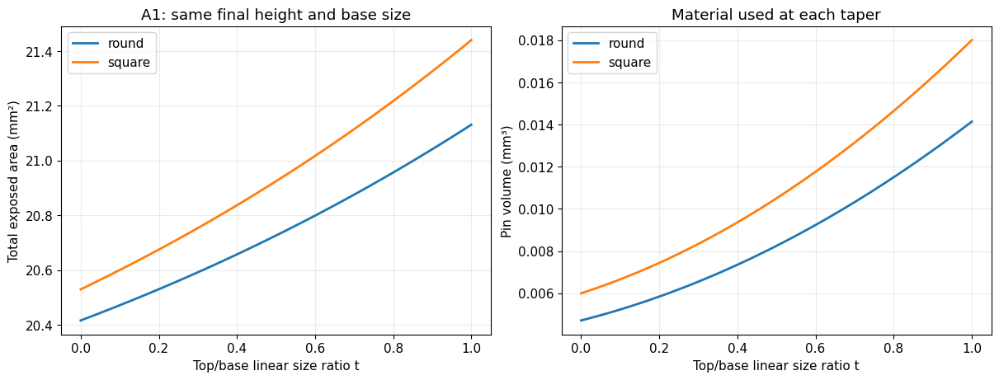

In [5]:
tt=np.linspace(0,1,101)
fig,axs=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for family in ['round','square']:
    q=geometry(family,REF_WIDTH,H_MAIN,tt,NREF)
    axs[0].plot(tt,q['area'],label=family,lw=2)
    axs[1].plot(tt,q['volume'],label=family,lw=2)
for ax in axs:ax.set_xlabel('Top/base linear size ratio t');ax.legend();ax.grid(alpha=.25)
axs[0].set(ylabel='Total exposed area (mm²)',title='A1: same final height and base size')
axs[1].set(ylabel='Pin volume (mm³)',title='Material used at each taper')
fig.savefig(OUT/'A1_taper.png',dpi=160);plt.show()


## A2. Check fairness: SAME individual footprint area instead of same width

**FIXED:** h, count, gap and individual footprint B = REF_WIDTH². For each t, circular and square pins also have equal top footprint t²B and equal volume NhB(1+t+t²)/3.

**VARIED:** cross-section family and taper. To achieve equal B, the round base diameter is $2\sqrt{B/\pi}$, while the square side is $\sqrt{B}$. The circular array therefore occupies a larger bounding envelope; the same count/gap must still fit. These dimensions are shown explicitly. This comparison does not impose equal diameter/side width.

At t = 1, equal-footprint square prisms have about **12.8% more added area** than cylinders (perimeter ratio 2/√π). This is a different ratio from the **27.3%** added-area advantage at equal bounding width in A.

In [6]:
BREF=REF_WIDTH**2
footprint=[]
for d in DESIGNS:
    w=2*np.sqrt(BREF/np.pi) if d['family']=='round' else np.sqrt(BREF)
    valid=bool(fits(REF_NX,REF_NY,w,REF_GAP) and feature_ok(w,H_MAIN,REF_GAP))
    q=geometry(d['family'],w,H_MAIN,d['t'],NREF)
    footprint.append(dict(label=d['label'],t=d['t'],width_mm=float(w),feasible=valid,
                         area_mm2=float(q['area']),volume_mm3=float(q['volume'])))
table([[r['label'],f"{r['width_mm']:.4f}",str(r['feasible']),f"{r['area_mm2']:.2f}" if r['feasible'] else 'excluded',f"{r['volume_mm3']:.3f}"] for r in footprint],
      ['Shape','Diameter / side (mm)','Fits constraints?','Area (mm²)','Volume (mm³)'])
for t in [0,.5,1]:
    vr=geometry('round',2*np.sqrt(BREF/np.pi),H_MAIN,t,NREF)['volume']
    vs=geometry('square',np.sqrt(BREF),H_MAIN,t,NREF)['volume']
    assert np.isclose(vr,vs)
save_csv(OUT/'A2_equal_footprint.csv',footprint)


| Shape | Diameter / side (mm) | Fits constraints? | Area (mm²) | Volume (mm³) |
|---|---|---|---|---|
| Cylinder | 0.0564 | True | 21.28 | 0.018 |
| Truncated cone | 0.0564 | True | 20.80 | 0.011 |
| Cone (reference) | 0.0564 | True | 20.45 | 0.006 |
| Square prism | 0.0500 | True | 21.44 | 0.018 |
| Truncated pyramid | 0.0500 | True | 20.92 | 0.011 |
| Pyramid (reference) | 0.0500 | True | 20.53 | 0.006 |

## Physical geometry viewer — these are actual pins, not an area surface

The first figure compares individual pins at **identical final height and base bounding width**. The second viewer shows the complete cathode reference array; buttons change shape. Drag to rotate, scroll to zoom. Axes have equal physical scale. Flat tops are drawn explicitly. All six designs use the reference array from study A, not optimized arrays from study B.

If interactive output is hidden by your Jupyter viewer, trust the notebook and rerun the cell. Self-contained HTML copies are saved in the results folder. The triangle mesh approximates circular surfaces for display only; all area formulas remain exact.

In [7]:
def mesh(family,w,h,t,nx=1,ny=1,g=0,center=(0.,0.)):
    k=20 if family=='round' else 4
    if family=='round':
        theta=np.linspace(0,2*np.pi,k,endpoint=False)
        ring=np.column_stack([np.cos(theta),np.sin(theta)])*w/2
    else:ring=np.array([[-1,-1],[1,-1],[1,1],[-1,1]])*w/2
    vertices=[];faces=[]
    for ix in range(nx):
        for iy in range(ny):
            cx=center[0]+(ix-(nx-1)/2)*(w+g)
            cy=center[1]+(iy-(ny-1)/2)*(w+g)
            off=len(vertices)
            vertices.extend([[cx+x,cy+y,0] for x,y in ring])
            if t==0:
                vertices.append([cx,cy,h])
                faces.extend([[off+j,off+(j+1)%k,off+k] for j in range(k)])
            else:
                vertices.extend([[cx+t*x,cy+t*y,h] for x,y in ring])
                vertices.append([cx,cy,h])
                for j in range(k):
                    q=(j+1)%k
                    faces.extend([[off+j,off+q,off+k+j],[off+q,off+k+q,off+k+j],[off+2*k,off+k+j,off+k+q]])
    return np.asarray(vertices),np.asarray(faces)

def mesh_trace(v,f,**kw):
    return go.Mesh3d(x=v[:,0],y=v[:,1],z=v[:,2],i=f[:,0],j=f[:,1],k=f[:,2],
                     color='#d7a246',flatshading=True,**kw)

def interactive(fig,name):
    fig.write_html(OUT/(name+'.html'),include_plotlyjs=True)
    display(HTML(fig.to_html(full_html=False,include_plotlyjs=True)))

if PLOTLY_AVAILABLE:
    fig=make_subplots(rows=2,cols=3,specs=[[{'type':'scene'}]*3]*2,subplot_titles=[d['label'] for d in DESIGNS])
    for i,d in enumerate(DESIGNS):
        v,f=mesh(d['family'],REF_WIDTH,H_MAIN,d['t'])
        fig.add_trace(mesh_trace(v,f,name=d['label']),row=i//3+1,col=i%3+1)
    fig.update_scenes(aspectmode='data',xaxis_title='x (mm)',yaxis_title='y (mm)',zaxis_title='Height (mm)')
    fig.update_layout(title='Actual shapes: same final height and base width',height=800,showlegend=False)
    interactive(fig,'physical_single_pins')
    fig=go.Figure()
    fig.add_trace(go.Mesh3d(x=[0,L,L,0],y=[0,0,W,W],z=[0,0,0,0],
                           i=[0,0],j=[1,2],k=[2,3],color='#4e819c',opacity=.6,name='Cathode face'))
    for i,d in enumerate(DESIGNS):
        v,f=mesh(d['family'],REF_WIDTH,H_MAIN,d['t'],REF_NX,REF_NY,REF_GAP,(L/2,W/2))
        fig.add_trace(mesh_trace(v,f,name=d['label'],visible=i==0))
    buttons=[dict(label=d['label'],method='update',args=[{'visible':[True]+[i==j for j in range(len(DESIGNS))]},
                 {'title':f"{d['label']}: {NREF} reference pins, h={H_MAIN:g} mm"}]) for i,d in enumerate(DESIGNS)]
    fig.update_layout(title=f'{DESIGNS[0]["label"]}: {NREF} reference pins, h={H_MAIN:g} mm',height=650,
        updatemenus=[dict(buttons=buttons,direction='down',x=0,y=1.15)],
        scene=dict(aspectmode='data',xaxis_title='Along cathode (mm)',yaxis_title='Across cathode (mm)',zaxis_title='Into gel (mm)'))
    interactive(fig,'physical_reference_arrays')
else:print('Install plotly to see physical 3D geometry.')


## B. At FIXED HEIGHT, which width and gap give the largest area?

**FIXED:** H_MAIN, cathode, margins, shape and top ratio per panel. **VARIED:** base width w and clear gap g. **CALCULATED:** maximum fitting integer row/column counts, total area and material volume. **Volume is not fixed.**

$$n_x=\left\lfloor\frac{L-2m+g}{w+g}\right\rfloor,\quad n_y=\left\lfloor\frac{W-2m+g}{w+g}\right\rfloor,\quad N=n_xn_y.$$

No row/column fractions are used. Every candidate uses the largest complete grid that fits; equal width/gap uses the same count across shapes. With positive added area per pin and no material budget, adding another fitting pin increases total area. Staggered arrays, partial rows and rotated bases are not included.

**Heatmaps:** x = base width, y = clear gap, colour = total area. The red star marks the best sampled feasible candidate in that panel. All panels share one colour scale. **3D surfaces show the same data** as width–gap–area, not the physical pin shape. Sharp steps occur when an integer row/column no longer fits.

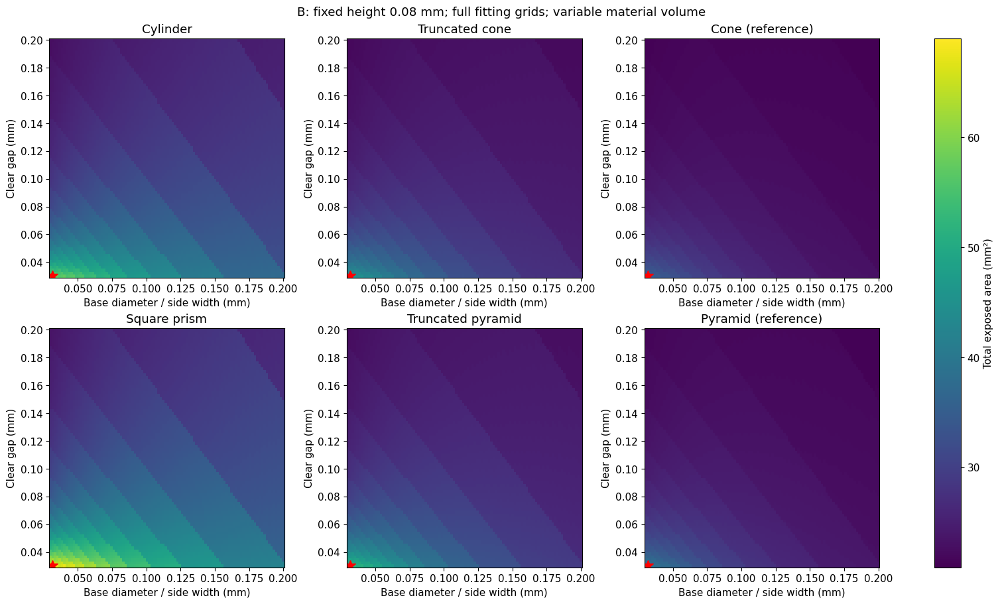

| Shape | Base width (mm) | Gap (mm) | Array/count | Area (mm²) | Vs flat | Volume (mm³) |
|---|---|---|---|---|---|---|
| Cylinder | 0.0317 | 0.030 | 322 × 15 = 4830 | 58.50 | 2.93× | 0.305 |
| Truncated cone | 0.0317 | 0.030 | 322 × 15 = 4830 | 46.16 | 2.31× | 0.178 |
| Cone (reference) | 0.0317 | 0.030 | 322 × 15 = 4830 | 35.81 | 1.79× | 0.102 |
| Square prism | 0.0317 | 0.030 | 322 × 15 = 4830 | 69.02 | 3.45× | 0.389 |
| Truncated pyramid | 0.0317 | 0.030 | 322 × 15 = 4830 | 53.30 | 2.67× | 0.227 |
| Pyramid (reference) | 0.0317 | 0.030 | 322 × 15 = 4830 | 40.13 | 2.01× | 0.130 |

In [8]:
def packed_study(h,ww=widths,gg=gaps):
    WX,GX=np.meshgrid(ww,gg)
    nx,ny=capacity(WX,GX);N=nx*ny
    valid=(N>0)&feature_ok(WX,h,GX)
    maps=[];winners=[]
    for d in DESIGNS:
        q=geometry(d['family'],WX,h,d['t'],N)
        area=np.where(valid,q['area'],np.nan)
        maps.append(dict(design=d,x=WX,y=GX,area=area,volume=np.where(valid,q['volume'],np.nan),
                         count=np.where(valid,N,np.nan)))
        if np.isfinite(area).any():
            iy,ix=np.unravel_index(np.nanargmax(area),area.shape)
            winners.append(dict(label=d['label'],family=d['family'],t=d['t'],height_mm=h,
                width_mm=float(WX[iy,ix]),gap_mm=float(GX[iy,ix]),nx=int(nx[iy,ix]),ny=int(ny[iy,ix]),
                count=int(N[iy,ix]),area_mm2=float(area[iy,ix]),ratio=float(area[iy,ix]/A0),
                volume_mm3=float(q['volume'][iy,ix])))
    return maps,winners

maps,best=packed_study(H_MAIN)
finite=[m['area'][np.isfinite(m['area'])] for m in maps]
finite=[a for a in finite if len(a)]
assert finite, 'No feasible designs. Adjust width, gap, height, margins or aspect limit.'
vmin=min(a.min() for a in finite);vmax=max(a.max() for a in finite)
fig,axs=plt.subplots(2,3,figsize=(15,9),constrained_layout=True)
for ax,m in zip(axs.flat,maps):
    im=ax.pcolormesh(m['x'],m['y'],m['area'],shading='auto',vmin=vmin,vmax=vmax,cmap='viridis')
    r=next((r for r in best if r['label']==m['design']['label']),None)
    if r:ax.plot(r['width_mm'],r['gap_mm'],'r*',ms=12)
    ax.set(title=m['design']['label'],xlabel='Base diameter / side width (mm)',ylabel='Clear gap (mm)')
fig.colorbar(im,ax=axs,label='Total exposed area (mm²)')
fig.suptitle(f'B: fixed height {H_MAIN:g} mm; full fitting grids; variable material volume')
fig.savefig(OUT/'B_fixed_height_heatmaps.png',dpi=170);plt.show()

def show_surfaces(entries,title,name):
    if PLOTLY_AVAILABLE:
        fig=make_subplots(rows=2,cols=3,specs=[[{'type':'surface'}]*3]*2,
                          subplot_titles=[e['label'] for e in entries])
        for i,e in enumerate(entries):
            fig.add_trace(go.Surface(x=e['x'],y=e['y'],z=e['area'],customdata=e['volume'],coloraxis='coloraxis',
                hovertemplate='x: %{x:.4f}<br>y: %{y:.4f}<br>Area: %{z:.3f} mm²<br>Material: %{customdata:.3f} mm³<extra></extra>'),row=i//3+1,col=i%3+1)
            scene='scene'+(str(i+1) if i else '')
            fig.update_layout(**{scene:dict(xaxis_title=e['xlabel'],yaxis_title=e['ylabel'],zaxis_title='Area (mm²)')})
        fig.update_layout(title=title,height=950,coloraxis=dict(colorscale='Viridis',colorbar_title='Area (mm²)'))
        interactive(fig,name)
    else:
        fig=plt.figure(figsize=(15,10),constrained_layout=True)
        for i,e in enumerate(entries,1):
            ax=fig.add_subplot(2,3,i,projection='3d')
            ax.plot_surface(e['x'],e['y'],e['area'],cmap='viridis')
            ax.set(title=e['label'],xlabel=e['xlabel'],ylabel=e['ylabel'],zlabel='Area (mm²)')
        fig.suptitle(title);plt.show()

entries=[dict(label=m['design']['label'],x=m['x'],y=m['y'],area=m['area'],volume=m['volume'],
              xlabel='Base diameter / side (mm)',ylabel='Clear gap (mm)') for m in maps]
show_surfaces(entries,f'B: FIXED HEIGHT {H_MAIN:g} mm | width–gap–area | volume varies','B_width_gap_area')
table([[r['label'],f"{r['width_mm']:.4f}",f"{r['gap_mm']:.3f}",f"{r['nx']} × {r['ny']} = {r['count']}",
        f"{r['area_mm2']:.2f}",f"{r['ratio']:.2f}×",f"{r['volume_mm3']:.3f}"] for r in best],
      ['Shape','Base width (mm)','Gap (mm)','Array/count','Area (mm²)','Vs flat','Volume (mm³)'])
save_csv(OUT/'B_best_sampled_designs.csv',best)


### B1. Explain the winner: count, volume and grid convergence

A star is a sampled maximum, not a universal optimum. If it reaches a minimum gap or width, that bound affects the answer. Different panels can have different optimal widths because taper changes net area per pin.

For cylinders on a large square grid at fixed height/gap, $(A-A_0)/A_0\approx\pi wh/(w+g)^2$, which peaks at w = g. The exact finite, very narrow cathode can behave differently. The refined search below keeps the same endpoints and doubles grid density. Exported B stars remain the coarse-grid winners; refined winners are saved separately.

Volume is also gel displacement if the full pin is inside gel. A displacement fraction is reported only when you supply a measured compartment volume.

In [9]:
RUN_REFINEMENT = True
refined=[]
if RUN_REFINEMENT:
    _,refined=packed_study(H_MAIN,np.linspace(WIDTH_MIN,WIDTH_MAX,2*N_WIDTH-1),
                           np.linspace(GAP_MIN,GAP_MAX,2*N_GAP-1))
    rows=[]
    for r in best:
        rr=next((x for x in refined if x['label']==r['label']),None)
        if rr:rows.append([r['label'],f"{r['area_mm2']:.4f}",f"{rr['area_mm2']:.4f}",f"{100*(rr['area_mm2']/r['area_mm2']-1):.3f}%"])
    table(rows,['Shape','Coarse area (mm²)','Refined area (mm²)','Improvement'])
    save_csv(OUT/'B_refined_best_designs.csv',refined)
if best:
    r=max(best,key=lambda x:x['area_mm2'])
    display(Markdown(f"**Best coarse-grid design at h = {H_MAIN:g} mm:** {r['label']}, {r['count']} pins, base width {r['width_mm']:.4f} mm, gap {r['gap_mm']:.4f} mm; **{r['area_mm2']:.2f} mm² ({r['ratio']:.2f}× flat)**, material {r['volume_mm3']:.3f} mm³."))
    if np.isclose(r['gap_mm'],GAP_MIN): print('The winning gap equals the assumed minimum gap.')
    if np.isclose(r['width_mm'],WIDTH_MIN): print('The winning width equals the assumed minimum width.')
    if COMPARTMENT_VOLUME_MM3 is not None:
        assert COMPARTMENT_VOLUME_MM3>0
        print(f"Full pin volume / supplied compartment volume: {100*r['volume_mm3']/COMPARTMENT_VOLUME_MM3:.2f}%")


| Shape | Coarse area (mm²) | Refined area (mm²) | Improvement |
|---|---|---|---|
| Cylinder | 58.5018 | 58.5018 | 0.000% |
| Truncated cone | 46.1558 | 46.1558 | 0.000% |
| Cone (reference) | 35.8094 | 35.8094 | 0.000% |
| Square prism | 69.0221 | 69.0221 | 0.000% |
| Truncated pyramid | 53.3025 | 53.3025 | 0.000% |
| Pyramid (reference) | 40.1291 | 40.1291 | 0.000% |

**Best coarse-grid design at h = 0.08 mm:** Square prism, 4830 pins, base width 0.0317 mm, gap 0.0300 mm; **69.02 mm² (3.45× flat)**, material 0.389 mm³.

The winning gap equals the assumed minimum gap.


## C. Area (z) vs clear gap (x) and number of pins (y)

**FIXED:** h = H_MAIN, base width = REF_WIDTH, one shape/taper per panel. **VARIED:** gap and integer N. Volume changes with count. Each point must fit at least one complete rectangular array with N = nx × ny. Every factorization is tried; incomplete rows/staggered layouts are not.

Each plotted dot is a feasible design. The output first reports how many points are feasible. It then displays a static 3D point plot (no JavaScript required), followed by a rotatable Plotly version if Plotly is installed. Point plots preserve isolated feasible integer counts without requiring a continuous surface through excluded designs.

If the static plots appear but the interactive figure does not, the data exist: the remaining issue is your Jupyter JavaScript/Plotly renderer. Open the saved C_gap_count_area.html in a browser. If there are zero feasible designs, check the printed dimensions and chosen constraints.

Area rises linearly with N at fixed pin dimensions. Gap changes which counts fit, not the area per pin. Missing points are infeasible, not zero-area designs.


Feasible designs: 39,738 / 219,120
Cathode 20 × 1 mm; fixed h=0.08 mm; base width=0.05 mm


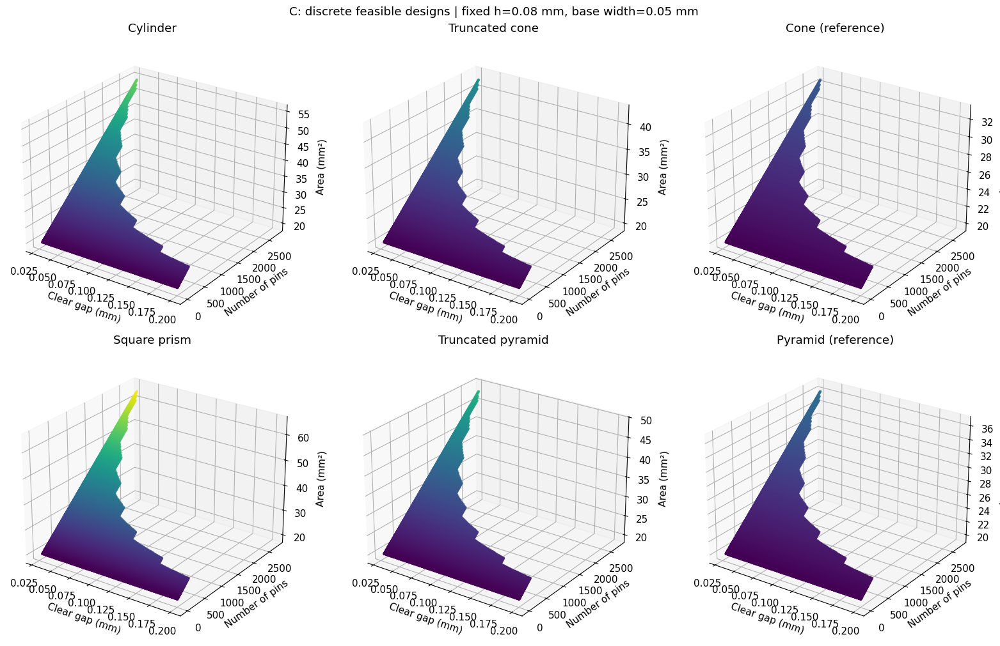

In [10]:
count_limit=int(np.prod(capacity(REF_WIDTH,GAP_MIN)))
counts=np.arange(1,count_limit+1)
CG,CN=np.meshgrid(gaps,counts)
valid=np.zeros(CG.shape,dtype=bool)
for i,N in enumerate(counts):
    for nx in range(1,int(np.sqrt(N))+1):
        if N%nx==0:
            ny=int(N)//nx
            valid[i] |= fits(nx,ny,REF_WIDTH,gaps) | fits(ny,nx,REF_WIDTH,gaps)
valid &= feature_ok(REF_WIDTH,H_MAIN,CG)
entries=[]
for d in DESIGNS:
    q=geometry(d['family'],REF_WIDTH,H_MAIN,d['t'],CN)
    entries.append(dict(label=d['label'],x=CG,y=CN,area=np.where(valid,q['area'],np.nan),
                         volume=np.where(valid,q['volume'],np.nan),xlabel='Clear gap (mm)',ylabel='Number of pins'))
# Discrete feasible arrays: draw points rather than a continuous surface.
print(f'Feasible designs: {valid.sum():,} / {valid.size:,}')
print(f'Cathode {L:g} × {W:g} mm; fixed h={H_MAIN:g} mm; base width={REF_WIDTH:g} mm')
if not np.any(valid):
    print('No designs fit. Check width, gap, cathode dimensions, margins and aspect-ratio limit.')
else:
    finite=np.concatenate([e['area'][np.isfinite(e['area'])] for e in entries])
    lo,hi=float(finite.min()),float(finite.max())
    fig=plt.figure(figsize=(16,10),constrained_layout=True)
    for i,e in enumerate(entries,1):
        good=np.isfinite(e['area'])
        ax=fig.add_subplot(2,3,i,projection='3d')
        ax.scatter(e['x'][good],e['y'][good],e['area'][good],
                   c=e['area'][good],cmap='viridis',vmin=lo,vmax=hi,s=5,alpha=.65)
        ax.set(title=e['label'],xlabel='Clear gap (mm)',ylabel='Number of pins',zlabel='Area (mm²)')
        ax.view_init(elev=25,azim=-55)
    fig.suptitle(f'C: discrete feasible designs | fixed h={H_MAIN:g} mm, base width={REF_WIDTH:g} mm')
    fig.savefig(OUT/'C_gap_count_points.png',dpi=160)
    plt.show()
    if PLOTLY_AVAILABLE:
        fig=make_subplots(rows=2,cols=3,specs=[[{'type':'scene'}]*3]*2,
                          subplot_titles=[e['label'] for e in entries])
        for i,e in enumerate(entries):
            good=np.isfinite(e['area'])
            # Lists avoid dependence on typed-array decoding in notebook renderers.
            fig.add_trace(go.Scatter3d(x=e['x'][good].tolist(),y=e['y'][good].tolist(),
                z=e['area'][good].tolist(),customdata=e['volume'][good].tolist(),mode='markers',
                marker=dict(size=2.5,color=e['area'][good].tolist(),coloraxis='coloraxis',opacity=.75),
                name=e['label'],hovertemplate='Gap: %{x:.3f} mm<br>Pins: %{y}<br>Area: %{z:.3f} mm²<br>Material: %{customdata:.3f} mm³<extra></extra>'),
                row=i//3+1,col=i%3+1)
        fig.update_scenes(xaxis_title='Clear gap (mm)',yaxis_title='Number of pins',zaxis_title='Area (mm²)')
        fig.update_layout(title=f'C: discrete feasible designs | h={H_MAIN:g} mm, base width={REF_WIDTH:g} mm',
                          height=1000,showlegend=False,coloraxis=dict(colorscale='Viridis',cmin=lo,cmax=hi))
        interactive(fig,'C_gap_count_area')
    else:
        print('Static plots above are available. For interactive rotation: %pip install plotly')


## D. Area (z) vs height (x) and radius / side width (y)

**FIXED:** gap D_GAP and exact array D_NX × D_NY. Shape/taper is fixed per panel. **VARIED:** final height and base size; volume is free. This is intentionally the one study where height varies continuously.

Round panels use **base radius R = w/2** on y. Square panels use **base side w** on y. A radius of 0.1 mm and square side of 0.1 mm are not the equal-width comparison; a radius of 0.1 corresponds to diameter 0.2. Layout fit and any optional aspect-ratio cap are enforced.

For a cylinder, ΔA = 2πNRh: doubling height or radius doubles **added** area at fixed other dimensions. Doubling radius uses four times the volume, while doubling height uses twice the volume. Width/count cannot both increase without eventually conflicting with available space.

Feasible points: 9,000 / 9,000
Fixed array: 10 × 2 = 20 pins; fixed clear gap: 0.2 mm


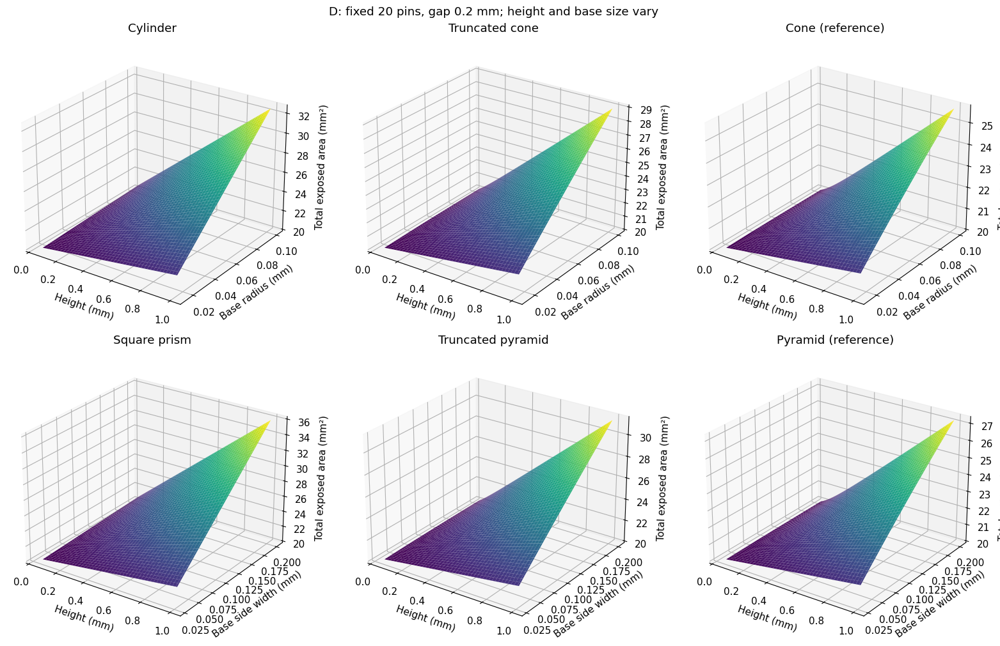

In [11]:
height_axis = np.linspace(min(HEIGHTS), max(HEIGHTS), 90)
HH, DW = np.meshgrid(height_axis, widths)

valid = (
    fits(D_NX, D_NY, DW, D_GAP)
    & feature_ok(DW, HH, D_GAP)
)

print(f"Feasible points: {valid.sum():,} / {valid.size:,}")
print(
    f"Fixed array: {D_NX} × {D_NY} = {D_NX * D_NY} pins; "
    f"fixed clear gap: {D_GAP:g} mm"
)

if not valid.any():
    raise ValueError(
        "No feasible designs. Check array count, gap, width range, "
        "cathode dimensions, margins and any aspect-ratio limit."
    )

entries = []

for d in DESIGNS:
    q = geometry(
        d["family"], DW, HH, d["t"], D_NX * D_NY
    )
    circular = d["family"] == "round"

    entries.append({
        "label": d["label"],
        "x": HH,
        "y": DW / 2 if circular else DW,
        "area": np.where(valid, q["area"], np.nan),
        "ylabel": (
            "Base radius (mm)"
            if circular else "Base side width (mm)"
        ),
    })

# Static Matplotlib plots: no Plotly, JavaScript or nbformat needed.
fig = plt.figure(figsize=(16, 10), constrained_layout=True)

for i, e in enumerate(entries, start=1):
    ax = fig.add_subplot(2, 3, i, projection="3d")

    ax.plot_surface(
        e["x"],
        e["y"],
        np.ma.masked_invalid(e["area"]),
        cmap="viridis",
        linewidth=0,
        antialiased=True,
    )

    ax.set(
        title=e["label"],
        xlabel="Height (mm)",
        ylabel=e["ylabel"],
        zlabel="Total exposed area (mm²)",
    )
    ax.view_init(elev=25, azim=-55)

fig.suptitle(
    f"D: fixed {D_NX * D_NY} pins, gap {D_GAP:g} mm; "
    "height and base size vary"
)

fig.savefig(OUT / "D_height_size_area_static.png", dpi=160)
plt.show()

## E. Repeat the packed-array comparison at several fixed heights

**FIXED within each height:** h, cathode and feature bounds. Shape, width and gap are searched as in B. Each point below represents the best sampled design for that shape at that height, not necessarily the same array across heights.

Without an aspect-ratio or material/gel-displacement limit, taller pins increase area in this geometric model. There is no reason for the geometric area to decrease at high h: any real reduction in performance from fragility, gel damage or bubbles lies outside the model. A height sweep therefore shows the cost/benefit of assumed penetration depths, not an experimentally optimal height.

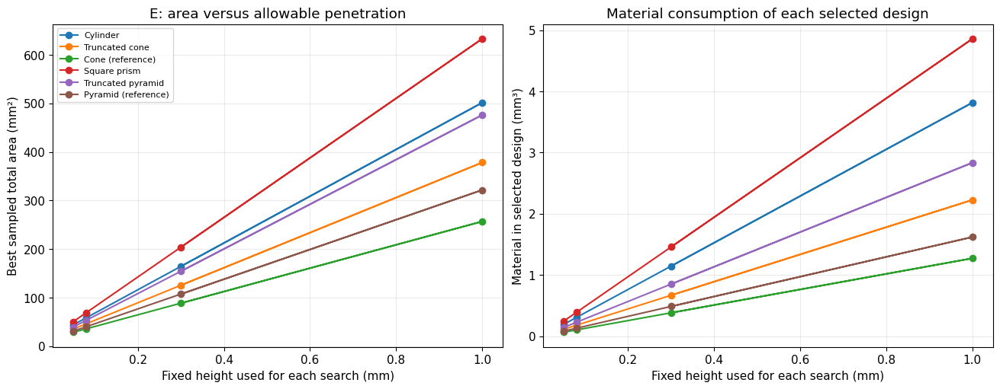

In [12]:
height_results=[]
for h in HEIGHTS:
    _,rs=packed_study(float(h))
    height_results.extend(rs)
fig,axs=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for d in DESIGNS:
    rs=[r for r in height_results if r['label']==d['label']]
    axs[0].plot([r['height_mm'] for r in rs],[r['area_mm2'] for r in rs],'-o',label=d['label'])
    axs[1].plot([r['height_mm'] for r in rs],[r['volume_mm3'] for r in rs],'-o',label=d['label'])
for ax in axs:ax.set_xlabel('Fixed height used for each search (mm)');ax.grid(alpha=.25)
axs[0].set(ylabel='Best sampled total area (mm²)',title='E: area versus allowable penetration')
axs[1].set(ylabel='Material in selected design (mm³)',title='Material consumption of each selected design')
axs[0].legend(fontsize=8);fig.savefig(OUT/'E_height_sweep.png',dpi=160);plt.show()
save_csv(OUT/'E_height_sweep.csv',height_results)


## F. Main design question: more pins or wider pins, for ONE fixed shape?

This section directly compares the two strategies rather than changing shape at the same time.

**FIXED:** selected shape and taper, final height, clear base gap, cathode footprint and margins. **VARIED:** base width and integer count. **CALCULATED:** total exposed area, added area, material used and whether a complete rectangular array fits. Material volume is free. This is a geometric comparison; performance, bubbles and adhesion are not modeled.

### First distinguish two questions
1. **If both strategies still fit:** increasing count adds sidewalls; increasing width makes each pin larger. Compare the same percentage change, not arbitrary increments.
2. **When the cathode space is the limiting resource:** increasing width removes fitting pins. Choose a width/count combination using the packing envelope, not the per-pin area alone.

For straight cylinders or square prisms at fixed height:

$$\Delta A=kNwh,\qquad V=cNw^2h,$$

where k = π and c = π/4 for cylinders, k = 4 and c = 1 for square prisms.

| Hypothetical change, if feasible | Added area | Total material |
|---|---|---|
| 10% more pins; same width | ×1.10 | ×1.10 |
| 10% wider; same count | ×1.10 | ×1.21 |
| Twice as many pins; same width | ×2 | ×2 |
| Twice the width; same count | ×2 | ×4 |

These factors concern **added area ΔA**, not A = A₀ + ΔA. Pin counts must be integers. Tapered shapes use their exact frustum equations below; the simple proportionality to width does not hold exactly for them.

**No universal answer follows from this table:** more pins is more material-efficient for straight pins, but wider pins may be preferable for fabrication/strength. On a full electrode, packing can dominate both strategies.

In [13]:
# Select ONE existing design label; change this and rerun section F.
F_LABEL = 'Cylinder'
# Examples: 'Square prism', 'Truncated cone', 'Truncated pyramid'
F_HEIGHT = H_MAIN
F_GAP = REF_GAP
F_BASE_WIDTH = REF_WIDTH
F_BASE_COUNT = REF_NX * REF_NY
F_NWIDTH = 120
F_DESIGN = next((d for d in DESIGNS if d['label'] == F_LABEL), None)
if F_DESIGN is None:
    raise ValueError('F_LABEL must match a label in DESIGNS.')
assert F_HEIGHT > 0 and F_GAP >= GAP_MIN

# Find an exact, complete rectangular layout for a requested integer count.
# The pins keep the specified gap. The array can leave unused space on the cathode.
def F_layout(count, width):
    if count < 1 or int(count) != count:
        return None
    if not bool(feature_ok(width, F_HEIGHT, F_GAP)):
        return None
    options=[]
    count=int(count)
    for nx in range(1, int(np.sqrt(count)) + 1):
        if count % nx == 0:
            ny=count//nx
            for a,b in {(nx,ny),(ny,nx)}:
                if bool(fits(a,b,width,F_GAP)):
                    options.append((int(a),int(b)))
    # Tie-break only for an illustrative layout; area depends on count, not factorization.
    return max(options,key=lambda xy:xy[0]) if options else None

F_family,F_t=F_DESIGN['family'],F_DESIGN['t']
print(f'FIXED: {F_LABEL}; t={F_t:g}; h={F_HEIGHT:g} mm; gap={F_GAP:g} mm; cathode={L:g} × {W:g} mm')
print('VARIED: count and base diameter / square side width. Total material volume varies.')


FIXED: Cylinder; t=1; h=0.08 mm; gap=0.05 mm; cathode=20 × 1 mm
VARIED: count and base diameter / square side width. Total material volume varies.


### F1. Controlled changes from the same baseline

Compare the same percentage changes, and also the intuitive doubling examples. The baseline is REF_NX × REF_NY pins at REF_WIDTH. Each candidate is checked against the same footprint, feature bounds and gap. A larger width does not automatically preserve the fitting count.

**INFEASIBLE** means the geometric area can be evaluated algebraically, but no permitted complete rectangular array fits; it is not a valid design. A ceil rounding is used for the 10% count increase, and its actual percentage is reported. No automatic change to height or gap is made to rescue a candidate.

In [14]:
strategies = [
    ('Baseline', F_BASE_COUNT, F_BASE_WIDTH),
    ('About 10% more pins', int(np.ceil(F_BASE_COUNT*1.10-1e-10)), F_BASE_WIDTH),
    ('10% wider pins', F_BASE_COUNT, F_BASE_WIDTH*1.10),
    ('Double pin count', 2*F_BASE_COUNT, F_BASE_WIDTH),
    ('Double pin width', F_BASE_COUNT, 2*F_BASE_WIDTH),
]
F_records=[]
base=geometry(F_family,F_BASE_WIDTH,F_HEIGHT,F_t,F_BASE_COUNT)
for label,count,w in strategies:
    layout=F_layout(count,w)
    q=geometry(F_family,w,F_HEIGHT,F_t,count)
    F_records.append(dict(strategy=label,count=int(count),width_mm=float(w),
        actual_count_change_percent=100*(count/F_BASE_COUNT-1),
        feasible=layout is not None,layout=str(layout),area_mm2=float(q['area']),
        added_area_mm2=float(q['added']),added_area_ratio=float(q['added']/base['added']),
        volume_mm3=float(q['volume']),material_ratio=float(q['volume']/base['volume'])))
table([[r['strategy'],r['count'],f"{r['width_mm']:.3f}",'YES' if r['feasible'] else 'INFEASIBLE',
        f"{r['area_mm2']:.2f}",f"{r['added_area_ratio']:.3f}×",f"{r['material_ratio']:.3f}×"] for r in F_records],
      ['Strategy','Pins','Width (mm)','Fits?','Area* (mm²)','Added area / baseline','Material / baseline'])
print('*Area for an infeasible row is hypothetical only, not an eligible design.')
print('Actual count change for the rounded 10% option:',F_records[1]['actual_count_change_percent'],'%')
save_csv(OUT/'F1_count_vs_width_strategies.csv',F_records)


| Strategy | Pins | Width (mm) | Fits? | Area* (mm²) | Added area / baseline | Material / baseline |
|---|---|---|---|---|---|---|
| Baseline | 90 | 0.050 | YES | 21.13 | 1.000× | 1.000× |
| About 10% more pins | 99 | 0.050 | YES | 21.24 | 1.100× | 1.100× |
| 10% wider pins | 90 | 0.055 | YES | 21.24 | 1.100× | 1.210× |
| Double pin count | 180 | 0.050 | YES | 22.26 | 2.000× | 2.000× |
| Double pin width | 90 | 0.100 | YES | 22.26 | 2.000× | 4.000× |

*Area for an infeasible row is hypothetical only, not an eligible design.
Actual count change for the rounded 10% option: 10.000000000000009 %


### F2. Full comparison: area vs WIDTH and COUNT at the SAME gap and height

**x:** base diameter / side width. **y:** integer pin count. **Colour and 3D z:** total exposed area. The layout is checked for every point using exact integer factorizations. Blank regions are infeasible. No count fractions or interpolation over missing designs is used.

A vertical slice increases count at fixed width; a horizontal slice increases width at fixed count. Points show the actual feasible samples. Static plots always display; Plotly is optional and the saved HTML can be opened separately.

The red line/star in the heatmap below identifies the maximum-fitting rectangular count at each width and the best sampled design on that boundary. At fixed positive height and dimensions, each added pin contributes positive area, so the maximum-count boundary contains the area maximum within the complete-grid layouts considered here.

Feasible sampled width/count pairs: 57,598 / 328,680
Best sampled: width 0.0443 mm, 2110 pins; area 43.48 mm² (2.17× flat)


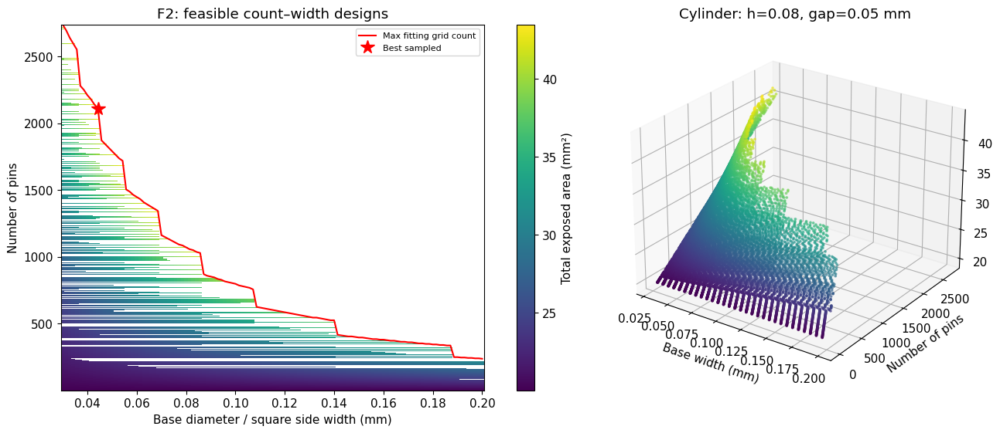

In [15]:
F_width_axis=np.linspace(WIDTH_MIN,WIDTH_MAX,F_NWIDTH)
F_nxmax,F_nymax=capacity(F_width_axis,F_GAP)
F_cap=F_nxmax*F_nymax
F_count_axis=np.arange(1,int(F_cap.max())+1)
if not len(F_count_axis):
    raise ValueError('No pin grid fits at the selected gap and width bounds.')
FW,FN=np.meshgrid(F_width_axis,F_count_axis)
F_valid=np.zeros(FW.shape,dtype=bool)
for i,count in enumerate(F_count_axis):
    for nx in range(1,int(np.sqrt(count))+1):
        if count%nx==0:
            ny=int(count)//nx
            F_valid[i] |= fits(nx,ny,F_width_axis,F_GAP) | fits(ny,nx,F_width_axis,F_GAP)
F_valid &= feature_ok(FW,F_HEIGHT,F_GAP)
F_values=geometry(F_family,FW,F_HEIGHT,F_t,FN)
F_area=np.where(F_valid,F_values['area'],np.nan)
if not np.isfinite(F_area).any():
    raise ValueError('No feasible width/count combinations under the selected constraints.')
F_envelope=geometry(F_family,F_width_axis,F_HEIGHT,F_t,F_cap)
F_envelope_valid=(F_cap>0)&feature_ok(F_width_axis,F_HEIGHT,F_GAP)
F_envelope_area=np.where(F_envelope_valid,F_envelope['area'],np.nan)
F_k=int(np.nanargmax(F_envelope_area))
F_wbest=float(F_width_axis[F_k]);F_nbest=int(F_cap[F_k]);F_abest=float(F_envelope_area[F_k])
# Verify best boundary candidate is truly feasible and matches the 2D sampled maximum.
assert F_layout(F_nbest,F_wbest) is not None
assert np.isclose(F_abest,np.nanmax(F_area))
print(f'Feasible sampled width/count pairs: {F_valid.sum():,} / {F_valid.size:,}')
print(f'Best sampled: width {F_wbest:.4f} mm, {F_nbest} pins; area {F_abest:.2f} mm² ({F_abest/A0:.2f}× flat)')
fig=plt.figure(figsize=(13,5.5),constrained_layout=True)
ax=fig.add_subplot(1,2,1)
im=ax.pcolormesh(FW,FN,F_area,shading='auto',cmap='viridis')
ax.plot(F_width_axis,np.where(F_envelope_valid,F_cap,np.nan),color='red',lw=1.5,label='Max fitting grid count')
ax.plot(F_wbest,F_nbest,'r*',ms=13,label='Best sampled')
ax.set(xlabel='Base diameter / square side width (mm)',ylabel='Number of pins',title='F2: feasible count–width designs')
ax.legend(fontsize=8);fig.colorbar(im,ax=ax,label='Total exposed area (mm²)')
ax=fig.add_subplot(1,2,2,projection='3d')
mask=np.isfinite(F_area)
# Limit the static point density for readability only; maximum selection uses all points.
ind=np.flatnonzero(mask);stride=max(1,int(np.ceil(len(ind)/15000)));take=ind[::stride]
ax.scatter(FW.ravel()[take],FN.ravel()[take],F_area.ravel()[take],c=F_area.ravel()[take],cmap='viridis',s=3,alpha=.55)
ax.set(xlabel='Base width (mm)',ylabel='Number of pins',zlabel='Area (mm²)',title=f'{F_LABEL}: h={F_HEIGHT:g}, gap={F_GAP:g} mm')
ax.view_init(elev=25,azim=-55)
fig.savefig(OUT/'F2_width_count_area.png',dpi=160);plt.show()
if PLOTLY_AVAILABLE:
    # Python lists avoid typed-array issues in older notebook renderers.
    fig=go.Figure(go.Scatter3d(x=FW.ravel()[take].tolist(),y=FN.ravel()[take].tolist(),
        z=F_area.ravel()[take].tolist(),customdata=F_values['volume'].ravel()[take].tolist(),mode='markers',
        marker=dict(size=2,color=F_area.ravel()[take].tolist(),colorscale='Viridis',colorbar=dict(title='Area mm²'),opacity=.65),
        hovertemplate='Width: %{x:.4f} mm<br>Pins: %{y}<br>Area: %{z:.3f} mm²<br>Material: %{customdata:.3f} mm³<extra></extra>'))
    fig.update_layout(title=f'F2: {F_LABEL} | fixed h={F_HEIGHT:g} mm, gap={F_GAP:g} mm',height=650,
        scene=dict(xaxis_title='Base diameter / side width (mm)',yaxis_title='Number of pins',zaxis_title='Area (mm²)'))
    interactive(fig,'F2_width_count_area')


### F3. Decision curve: width increases, but fewer pins fit

This is the most direct answer when the electrode footprint is the limiting resource. It uses the **same shape, fixed height and fixed gap** throughout. At each width, fill the maximum complete rectangular grid, then plot count, total exposed area and material consumption.

For straight cylindrical pins on an ideal large square array:

$$N\approx\frac{A_0}{(w+g)^2},\quad \Delta A\approx\frac{A_0\pi wh}{(w+g)^2}.$$

At constant h and g, the approximate best diameter is w = g. For square prisms π becomes 4 and the same approximate optimal width follows. Your finite 20 × 1 mm cathode can lose entire rows, so use the exact staircase count/area curves rather than treating that approximation as the final answer.

**Interpretation:** at equal count a wider pin helps; at maximum packing a wider pin may reduce total area by removing too many neighbors. A large count is not automatically superior unless you also state the pin dimensions. The most defensible selection is an explicit (width, count, height, gap) combination, together with the constraints and material consumption.

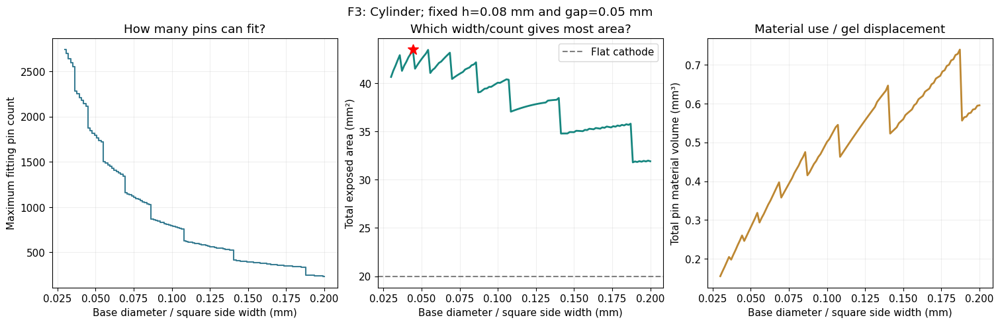

**For this straight-pin shape:** the same percentage increase in count or width gives the same percentage increase in added area, if both fit. More pins require less additional material for that gain. On the full cathode, the optimal sampled width/count is given by the area peak above.

Width/count optimum is conditional on the selected gap, height and sampled width range, not a mechanical/electrical optimum.


In [16]:
fig,axs=plt.subplots(1,3,figsize=(15,4.8),constrained_layout=True)
axs[0].step(F_width_axis,np.where(F_envelope_valid,F_cap,np.nan),where='mid',color='#397d93')
axs[0].set(ylabel='Maximum fitting pin count',title='How many pins can fit?')
axs[1].plot(F_width_axis,F_envelope_area,color='#16867f',lw=2)
axs[1].plot(F_wbest,F_abest,'r*',ms=12)
axs[1].axhline(A0,color='gray',ls='--',label='Flat cathode');axs[1].legend()
axs[1].set(ylabel='Total exposed area (mm²)',title='Which width/count gives most area?')
axs[2].plot(F_width_axis,np.where(F_envelope_valid,F_envelope['volume'],np.nan),color='#bd8732',lw=2)
axs[2].set(ylabel='Total pin material volume (mm³)',title='Material use / gel displacement')
for ax in axs:
    ax.set_xlabel('Base diameter / square side width (mm)');ax.grid(alpha=.2)
fig.suptitle(f'F3: {F_LABEL}; fixed h={F_HEIGHT:g} mm and gap={F_GAP:g} mm')
fig.savefig(OUT/'F3_packing_tradeoff.png',dpi=160);plt.show()
F_curve=[]
for j,w in enumerate(F_width_axis):
    if F_envelope_valid[j]:
        F_curve.append(dict(width_mm=float(w),count=int(F_cap[j]),nx=int(F_nxmax[j]),ny=int(F_nymax[j]),
            height_mm=float(F_HEIGHT),gap_mm=float(F_GAP),area_mm2=float(F_envelope_area[j]),volume_mm3=float(F_envelope['volume'][j])))
save_csv(OUT/'F3_packing_tradeoff.csv',F_curve)
if F_family in ('round','square') and F_t==1:
    display(Markdown('**For this straight-pin shape:** the same percentage increase in count or width gives the same percentage increase in added area, if both fit. More pins require less additional material for that gain. On the full cathode, the optimal sampled width/count is given by the area peak above.'))
else:
    display(Markdown('**For this tapered shape:** use the exact F1 table rather than the straight-pin percentage rule. The F3 area peak gives the best sampled width/count at the chosen height, gap and taper.'))
print('Width/count optimum is conditional on the selected gap, height and sampled width range, not a mechanical/electrical optimum.')


The jumps happen because the number of pins must be an integer. As width increases, a whole row or column can suddenly stop fitting.

## 3. What do these comparisons suggest?

1. **Shape at identical dimensions (A):** straight pins maximize area within their taper family. Truncation removes the pointed apex but reduces area relative to straight pins of the same final height/base. It may still be useful for assembly; this notebook does not prove an adhesion benefit.
2. **Normalization matters (A2):** square prisms have about 27.3% more added area than cylinders at equal diameter/side width, but about 12.8% more at equal individual footprint. Do not confuse these comparisons or ratios of added area with total area.
3. **More pins or larger pins (B/C/D):** more identical pins add area; larger pins add area per pin but displace neighbors. Use B to assess the balance on your finite cathode.
4. **Height (E):** more height adds geometric area and material, but must be bounded by practical penetration, mechanical and assembly requirements.
5. **No universal cathode winner:** practical selection still requires checking actual gel contact, retention, voltage at fixed current, gas/bubbles and gel integrity.

### Symbols and units
A₀ = LW; N = total pin count; h = final height; w = base diameter/square side; R = w/2 for round shapes; t = top/base linear ratio; g = clear gap; pitch = w+g. A is total exposed area, ΔA = A−A₀, and gain (%) = 100(A/A₀−1). All lengths mm, areas mm², volumes mm³.

### Explicit assumptions
Full gel contact on remaining base, sidewalls and tops; rigid perfect shapes; no rounding or roughness; square-pitch complete rectangular grids; no overlap; no chemistry, transport or electrochemistry. Pointed references have t=0; the chosen truncation ratio is an assumption. An optional aspect-ratio cap is an imposed envelope constraint, not a validated strength criterion. Pins displace gel; actual compartment volume is required to quantify that fraction.

### Where files are saved
PNG figures, CSV comparisons, parameter JSON and self-contained rotatable HTML plots are written into `fixed_height_cathode_results/<setup>/`. Parameter surfaces show design variables and area; physical meshes show actual spatial geometry. The notebook contains example outputs but should be rerun after changing any setting.

In [17]:
config=dict(setup=SETUP,L=L,W=W,margin=MARGIN,height_main=H_MAIN,heights=HEIGHTS,
    width_min=WIDTH_MIN,width_max=WIDTH_MAX,gap_min=GAP_MIN,gap_max=GAP_MAX,
    n_width=N_WIDTH,n_gap=N_GAP,max_aspect_ratio=MAX_ASPECT_RATIO,truncation_ratio=T_TRUNCATED,
    reference_width=REF_WIDTH,reference_gap=REF_GAP,reference_nx=REF_NX,reference_ny=REF_NY,
    D_nx=D_NX,D_ny=D_NY,D_gap=D_GAP,compartment_volume_mm3=COMPARTMENT_VOLUME_MM3)
(OUT/'parameters.json').write_text(json.dumps(config,indent=2))
print('Results saved in:',OUT.resolve())
print('Review A for a controlled shape comparison, B for packing optimization, C/D for isolated effects, and E for height sensitivity.')


Results saved in: /Users/parissaalavi/Downloads/Molesense_presentation/fixed_height_cathode_results/mini
Review A for a controlled shape comparison, B for packing optimization, C/D for isolated effects, and E for height sensitivity.
